# A field seen through binary data

A smooth periodic field `f` on 128 pixels, with a Gaussian-process prior. At each pixel we
only learn a yes/no label, more likely "yes" where the field is high:
`P(label = 1) = Phi(a f)` with `Phi` the standard normal CDF (a probit model).

The labels say little about the field's exact value, so its posterior is skewed at many
pixels. This example also shows how to write a likelihood by hand.

In [1]:
from dataclasses import replace

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jax.scipy.special import log_ndtr
from jax.scipy.stats import norm

import mgsl

jax.config.update("jax_enable_x64", True)

## The prior: a whitened Gaussian process

mgsl needs a latent with a standard-normal prior. A stationary periodic field is white noise
filtered in Fourier space: `f = ifft(sqrt(P) * fft(x))` with `x ~ N(0, I)` and power
spectrum `P` (here squared-exponential, correlation length `ell` pixels, unit variance).

In [2]:
n, ell = 128, 6.0
k = np.minimum(np.arange(n), n - np.arange(n))  # frequency index of each Fourier mode
power = np.exp(-0.5 * (2 * np.pi * k * ell / n) ** 2)
power = jnp.asarray(power / power.mean())  # unit variance per pixel


def field(x):
    return jnp.fft.ifft(jnp.sqrt(power) * jnp.fft.fft(x)).real

## Simulated data

A true field drawn from the prior, and one label per pixel.

In [3]:
a = 3.0  # how sharply the labels follow the sign of the field
rng = np.random.default_rng(1)
f_true = np.asarray(field(jnp.asarray(rng.normal(size=n))))
labels = rng.uniform(size=n) < norm.cdf(a * f_true)
sign = jnp.where(labels, 1.0, -1.0)  # +1 for "yes", -1 for "no"

## The likelihood, written by hand

`log p(labels | x) = sum_i log Phi(sign_i a f_i)`. mgsl also needs the Fisher metric of
the noise model, `F_i = a^2 phi(a f_i)^2 / (Phi(a f_i) Phi(-a f_i))` per pixel (`phi` the
normal density), pulled back to the latent: `J^T F J v`, with `J` the Jacobian of `field`.
`jax.jvp` and `jax.vjp` apply `J` and `J^T` without building them.

In [4]:
def log_likelihood(x):
    return jnp.sum(log_ndtr(sign * a * field(x)))


def fisher_weights(x):
    eta = a * field(x)
    return a**2 * jnp.exp(2 * norm.logpdf(eta) - log_ndtr(eta) - log_ndtr(-eta))


def fisher(x, v):  # J^T F J v
    _, jv = jax.jvp(field, (x,), (v,))
    _, vjp = jax.vjp(field, x)
    return vjp(fisher_weights(x) * jv)[0]


def fisher_sqrt(x, z):  # J^T F^(1/2) z
    _, vjp = jax.vjp(field, x)
    return vjp(jnp.sqrt(fisher_weights(x)) * z)[0]


lik = mgsl.Likelihood(
    log_likelihood,
    fisher,
    fisher_sqrt,
    data_shape=jax.ShapeDtypeStruct((n,), jnp.float64),
)
mgsl.check_likelihood(lik, jnp.zeros(n), jax.random.key(0));  # raises if the pieces disagree

## Sampling

In [5]:
options = mgsl.MGVIOptions(
    n_samples_mgvi=4,
    n_iter_mgvi=1,
    newton=mgsl.NewtonOptions(maxiter=5),
)
fit = mgsl.mgvi_fit(jax.random.key(1), lik, jnp.zeros(n), replace(options, n_iter_mgvi=10))

schedule = mgsl.Schedule(n_paths=512, tau_start=1e-2, tau_final=1e4, n_tau=48)
result = mgsl.sample(jax.random.key(2), lik, fit.mean, schedule, options, vectorize=True)
f_samples = np.asarray(jax.vmap(field)(jnp.asarray(result.samples)))  # (512, 128) fields

mgsl  step 1/47  tau=10^-2.00  1.34 s  ESS fraction median 0.60, min 0.10  failures 0


mgsl  step 2/47  tau=10^-1.87  0.13 s  ESS fraction median 0.62, min 0.09  failures 0


mgsl  step 3/47  tau=10^-1.74  0.13 s  ESS fraction median 0.60, min 0.09  failures 0


mgsl  step 4/47  tau=10^-1.62  0.13 s  ESS fraction median 0.63, min 0.05  failures 0


mgsl  step 5/47  tau=10^-1.49  0.13 s  ESS fraction median 0.61, min 0.10  failures 0


mgsl  step 6/47  tau=10^-1.36  0.13 s  ESS fraction median 0.62, min 0.11  failures 0


... (38 outputs left out)

mgsl  step 45/47  tau=10^3.62  0.05 s  ESS fraction median 1.00, min 1.00  failures 0


mgsl  step 46/47  tau=10^3.74  0.05 s  ESS fraction median 1.00, min 1.00  failures 0


mgsl  step 47/47  tau=10^3.87  0.06 s  ESS fraction median 1.00, min 1.00  failures 0


mgsl  terminal fit  tau=10^4.00  1.21 s  ESS fraction median 1.00, min 1.00  failures 0


## The field

The posterior median and 68% / 95% intervals of the field, the true field, and the labels
(ticks at the top for "yes", at the bottom for "no").

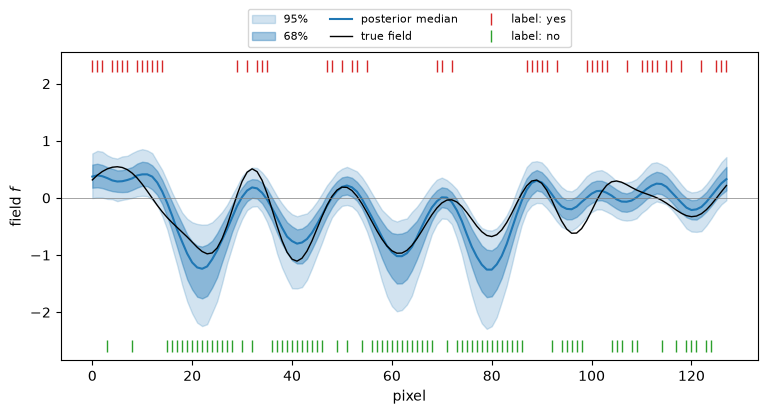

In [6]:
pixels = np.arange(n)
lo95, lo68, median, hi68, hi95 = np.percentile(f_samples, [2.5, 16, 50, 84, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(pixels, lo95, hi95, color="C0", alpha=0.2, label="95%")
ax.fill_between(pixels, lo68, hi68, color="C0", alpha=0.4, label="68%")
ax.plot(pixels, median, color="C0", label="posterior median")
ax.plot(pixels, f_true, color="k", lw=1, label="true field")
ax.plot(pixels[labels], np.full(labels.sum(), 2.3), "|", color="C3", ms=8, label="label: yes")
ax.plot(pixels[~labels], np.full((~labels).sum(), -2.6), "|", color="C2", ms=8, label="label: no")
ax.axhline(0, color="gray", lw=0.5)
ax.set_xlabel("pixel")
ax.set_ylabel("field $f$")
ax.legend(ncol=3, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.show()

## Skewed marginals

The posterior of a single pixel, compared with a Gaussian of the same mean and standard
deviation. Where the labels only bound the field from one side, the posterior is skewed.

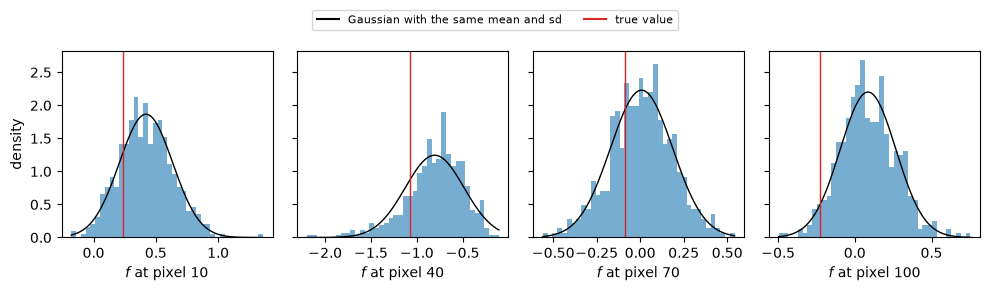

In [7]:
chosen = [10, 40, 70, 100]
fig, axes = plt.subplots(1, len(chosen), figsize=(10, 2.6), sharey=True)
for ax, i in zip(axes, chosen):
    values = f_samples[:, i]
    grid = np.linspace(values.min(), values.max(), 200)
    ax.hist(values, bins=40, density=True, color="C0", alpha=0.6)
    ax.plot(grid, norm.pdf(grid, values.mean(), values.std()), color="k", lw=1)
    ax.axvline(f_true[i], color="C3", lw=1)
    ax.set_xlabel(f"$f$ at pixel {i}")
axes[0].set_ylabel("density")
axes[0].plot([], [], color="k", label="Gaussian with the same mean and sd")
axes[0].plot([], [], color="C3", label="true value")
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

## Diagnostics

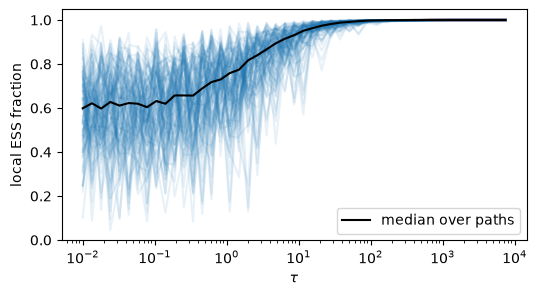

solver failures: {'draw_cg_capped': 0, 'newton_cg_capped': 0, 'cg_breakdowns': 0, 'sd_fallbacks': 0, 'line_search_failures': 0, 'nonfinite': 0}


In [8]:
d = result.diagnostics
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogx(d.taus, d.ess_fraction[:100].T, color="C0", alpha=0.1)
ax.semilogx(d.taus, np.median(d.ess_fraction, 0), color="k", label="median over paths")
ax.set_xlabel(r"$\tau$")
ax.set_ylabel("local ESS fraction")
ax.legend()
plt.show()

print("solver failures:", result.failures.totals())